### Import libraries

In [2]:
# Import pandas to work with tabular data
import pandas as pd

# Import numpy for numerical operations
import numpy as np

# Import matplotlib for creating graphs
import matplotlib.pyplot as plt

# Import seaborn for data visualization
import seaborn as sns

# Import train_test_split to divide data into training and testing sets
from sklearn.model_selection import train_test_split

# Import tools to handle missing values and scale features
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Import Pipeline to combine preprocessing and model training
from sklearn.pipeline import Pipeline

# Import the four classification algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

# Import evaluation metrics to measure model performance
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Print a message to confirm that the imports worked
print("All libraries imported successfully!")

All libraries imported successfully!


### Load the cleaned traffic dataset

In [4]:
# Import pandas to read the CSV file
import pandas as pd

# Load the cleaned traffic dataset from the processed data folder
df = pd.read_csv(r"C:\Users\KIIT\gfg_project\GFG_project\data\processed\urban_traffic_cleaned.csv")

# Display the number of rows and columns in the dataset
print("Dataset shape:", df.shape)

# Display the column names
print("\nColumn names:")
print(df.columns.tolist())

# Display the first five rows of the dataset
print("\nFirst five rows:")
display(df.head())

Dataset shape: (69120, 25)

Column names:
['timestamp', 'intersection_id', 'hour', 'minute', 'day_of_week', 'is_weekend', 'is_holiday', 'event_nearby', 'temperature_c', 'rain_mm_15min', 'road_capacity_veh_15min', 'vehicle_count', 'avg_speed_kmh', 'vehicle_density_per_km', 'avg_waiting_time_sec', 'queue_length_veh', 'incident_flag', 'prev_count_15min', 'prev_count_1h', 'count_same_time_yesterday', 'count_same_time_last_week', 'rolling_mean_1h', 'target_next_count', 'target_congestion', 'n_imputed_sensor_values']

First five rows:


,timestamp,intersection_id,hour,minute,day_of_week,is_weekend,is_holiday,event_nearby,temperature_c,rain_mm_15min,...,queue_length_veh,incident_flag,prev_count_15min,prev_count_1h,count_same_time_yesterday,count_same_time_last_week,rolling_mean_1h,target_next_count,target_congestion,n_imputed_sensor_values
0,2025-01-06 00:00:00,INT_01_CBD,0,0,0,0,0,0,2.6,0.0,...,1.5,0,NaN,NaN,NaN,NaN,NaN,36.0,Low,0
1,2025-01-06 00:15:00,INT_01_CBD,0,15,0,0,0,0,2.7,0.0,...,0.3,0,23.0,NaN,NaN,NaN,NaN,28.0,Low,0
2,2025-01-06 00:30:00,INT_01_CBD,0,30,0,0,0,0,2.4,0.0,...,0.0,0,36.0,NaN,NaN,NaN,NaN,33.0,Low,0
3,2025-01-06 00:45:00,INT_01_CBD,0,45,0,0,0,0,1.5,0.0,...,0.4,0,28.0,NaN,NaN,NaN,NaN,19.0,Low,0
4,2025-01-06 01:00:00,INT_01_CBD,1,0,0,0,0,0,3.1,0.0,...,0.0,0,33.0,23.0,NaN,NaN,30.0,32.0,Low,0


### Check the dataset and target column

In [6]:
# Display the number of rows and columns
print("Dataset size:", df.shape)

# Display the names of all columns
print("\nColumn names:")
for column in df.columns:
    print(column)

# Check the data types of each column
print("\nColumn data types:")
print(df.dtypes)

# Count missing values in each column
print("\nMissing values:")
print(df.isnull().sum())

# Check whether the target column exists
if "target_congestion" in df.columns:
    print("\nTarget column 'target_congestion' found!")

    # Display the number of records in each congestion class
    print("\nCongestion class distribution:")
    print(df["target_congestion"].value_counts(dropna=False))
else:
    print("\nTarget column 'target_congestion' was not found.")

Dataset size: (69120, 25)

Column names:
timestamp
intersection_id
hour
minute
day_of_week
is_weekend
is_holiday
event_nearby
temperature_c
rain_mm_15min
road_capacity_veh_15min
vehicle_count
avg_speed_kmh
vehicle_density_per_km
avg_waiting_time_sec
queue_length_veh
incident_flag
prev_count_15min
prev_count_1h
count_same_time_yesterday
count_same_time_last_week
rolling_mean_1h
target_next_count
target_congestion
n_imputed_sensor_values

Column data types:
timestamp                     object
intersection_id               object
hour                           int64
minute                         int64
day_of_week                    int64
is_weekend                     int64
is_holiday                     int64
event_nearby                   int64
temperature_c                float64
rain_mm_15min                float64
road_capacity_veh_15min        int64
vehicle_count                  int64
avg_speed_kmh                float64
vehicle_density_per_km       float64
avg_waiting_time_sec  

### Prepare the features and target

In [7]:
# Remove rows where the target value is missing
df = df.dropna(subset=["target_congestion"]).copy()

# Separate the target column from the input data
y = df["target_congestion"]

# Remove the target and timestamp from the input features
X = df.drop(
    columns=["target_congestion", "timestamp"],
    errors="ignore"
)

# Keep only numeric columns for model training
X = X.select_dtypes(include=["number"])

# Remove columns that contain only missing values
X = X.dropna(axis=1, how="all")

# Display the input features and target
print("Number of input rows:", X.shape[0])
print("Number of input features:", X.shape[1])

print("\nFeatures used for training:")
print(X.columns.tolist())

print("\nTarget classes:")
print(y.value_counts())

# Check whether the input and target have matching row counts
print("\nInput and target rows match:", len(X) == len(y))

Number of input rows: 69116
Number of input features: 22

Features used for training:
['hour', 'minute', 'day_of_week', 'is_weekend', 'is_holiday', 'event_nearby', 'temperature_c', 'rain_mm_15min', 'road_capacity_veh_15min', 'vehicle_count', 'avg_speed_kmh', 'vehicle_density_per_km', 'avg_waiting_time_sec', 'queue_length_veh', 'incident_flag', 'prev_count_15min', 'prev_count_1h', 'count_same_time_yesterday', 'count_same_time_last_week', 'rolling_mean_1h', 'target_next_count', 'n_imputed_sensor_values']

Target classes:
target_congestion
Low         42575
Moderate    15800
Severe       5744
High         4997
Name: count, dtype: int64

Input and target rows match: True


### Split data into training and testing sets

In [8]:
# Split the dataset into training and testing sets
# 80% of the data will train the models
# 20% of the data will test the models

X_train, X_test, y_train, y_test = train_test_split(
    X,                  # Input features
    y,                  # Target congestion classes
    test_size=0.20,     # Use 20% of the data for testing
    random_state=42,    # Keep the split reproducible
    stratify=y          # Preserve class proportions in both sets
)

# Display the number of training and testing rows
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

# Display the number of target labels in each set
print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training data: (55292, 22)
Testing data: (13824, 22)

Training target distribution:
target_congestion
Low         34059
Moderate    12640
Severe       4595
High         3998
Name: count, dtype: int64

Testing target distribution:
target_congestion
Low         8516
Moderate    3160
Severe      1149
High         999
Name: count, dtype: int64


### Train the Logistic Regression model

In [9]:
# Create a pipeline for Logistic Regression
logistic_model = Pipeline([
    # Fill missing numeric values using the median of each feature
    ("imputer", SimpleImputer(strategy="median")),

    # Scale features so they have comparable ranges
    ("scaler", StandardScaler()),

    # Create the Logistic Regression classifier
    ("classifier", LogisticRegression(max_iter=1000))
])

# Train the model using the training dataset
logistic_model.fit(X_train, y_train)

# Print a message after successful training
print("Logistic Regression model trained successfully!")

# Predict congestion classes for the test dataset
y_pred_lr = logistic_model.predict(X_test)

# Display the first 10 predicted classes
print("\nFirst 10 predictions:")
print(y_pred_lr[:10])

Logistic Regression model trained successfully!

First 10 predictions:
['Low' 'High' 'Moderate' 'Low' 'Low' 'Low' 'Moderate' 'High' 'Moderate'
 'Moderate']


### Evaluate Logistic Regression

In [10]:
# Calculate the accuracy of Logistic Regression
lr_accuracy = accuracy_score(y_test, y_pred_lr)

# Calculate weighted precision
lr_precision = precision_score(
    y_test, y_pred_lr,
    average="weighted",
    zero_division=0
)

# Calculate weighted recall
lr_recall = recall_score(
    y_test, y_pred_lr,
    average="weighted",
    zero_division=0
)

# Calculate weighted F1 score
lr_f1 = f1_score(
    y_test, y_pred_lr,
    average="weighted",
    zero_division=0
)

# Display all evaluation scores
print("Logistic Regression Performance")
print("--------------------------------")
print(f"Accuracy  : {lr_accuracy:.4f}")
print(f"Precision : {lr_precision:.4f}")
print(f"Recall    : {lr_recall:.4f}")
print(f"F1 Score  : {lr_f1:.4f}")

Logistic Regression Performance
--------------------------------
Accuracy  : 0.9915
Precision : 0.9915
Recall    : 0.9915
F1 Score  : 0.9915


### Train the SVC model

In [11]:
# Create a pipeline for the SVC model
svc_model = Pipeline([
    # Fill missing values using the median of each feature
    ("imputer", SimpleImputer(strategy="median")),

    # Scale the features because SVC is sensitive to feature scales
    ("scaler", StandardScaler()),

    # Create the Support Vector Classifier
    ("classifier", SVC(kernel="rbf"))
])

# Train SVC using the training dataset
svc_model.fit(X_train, y_train)

# Display a success message
print("SVC model trained successfully!")

# Predict congestion classes for the test dataset
y_pred_svc = svc_model.predict(X_test)

# Display the first 10 predictions
print("\nFirst 10 predictions:")
print(y_pred_svc[:10])

SVC model trained successfully!

First 10 predictions:
['Low' 'High' 'Low' 'Moderate' 'Low' 'Low' 'Moderate' 'High' 'Moderate'
 'Moderate']


### Evaluate SVC performance

In [12]:
# Calculate the accuracy of the SVC model
svc_accuracy = accuracy_score(y_test, y_pred_svc)

# Calculate weighted precision
svc_precision = precision_score(
    y_test, y_pred_svc,
    average="weighted",
    zero_division=0
)

# Calculate weighted recall
svc_recall = recall_score(
    y_test, y_pred_svc,
    average="weighted",
    zero_division=0
)

# Calculate weighted F1 score
svc_f1 = f1_score(
    y_test, y_pred_svc,
    average="weighted",
    zero_division=0
)

# Display the evaluation results
print("SVC Model Performance")
print("---------------------")
print(f"Accuracy  : {svc_accuracy:.4f}")
print(f"Precision : {svc_precision:.4f}")
print(f"Recall    : {svc_recall:.4f}")
print(f"F1 Score  : {svc_f1:.4f}")

SVC Model Performance
---------------------
Accuracy  : 0.9729
Precision : 0.9728
Recall    : 0.9729
F1 Score  : 0.9728


### Train the KNN Classification Model

In [14]:
# Create a pipeline for the KNN classification model
knn_model = Pipeline([
    # Fill missing values using the median of each feature
    ("imputer", SimpleImputer(strategy="median")),

    # Scale features because KNN uses distances between data points
    ("scaler", StandardScaler()),

    # Create the KNN classifier using 5 nearest neighbors
    ("classifier", KNeighborsClassifier(n_neighbors=5))
])

# Train the KNN model using the training dataset
knn_model.fit(X_train, y_train)

# Print a message after successful training
print("KNN model trained successfully!")

# Predict congestion classes for the test dataset
y_pred_knn = knn_model.predict(X_test)

# Display the first 10 predicted classes
print("\nFirst 10 predictions:")
print(y_pred_knn[:10])

KNN model trained successfully!

First 10 predictions:
['Moderate' 'High' 'Low' 'Moderate' 'Low' 'Low' 'Moderate' 'High'
 'Moderate' 'Moderate']


### Evaluate KNN performance

In [15]:
# Calculate the accuracy of the KNN model
knn_accuracy = accuracy_score(y_test, y_pred_knn)

# Calculate weighted precision
knn_precision = precision_score(
    y_test, y_pred_knn,
    average="weighted",
    zero_division=0
)

# Calculate weighted recall
knn_recall = recall_score(
    y_test, y_pred_knn,
    average="weighted",
    zero_division=0
)

# Calculate weighted F1 score
knn_f1 = f1_score(
    y_test, y_pred_knn,
    average="weighted",
    zero_division=0
)

# Display the evaluation results
print("KNN Model Performance")
print("---------------------")
print(f"Accuracy  : {knn_accuracy:.4f}")
print(f"Precision : {knn_precision:.4f}")
print(f"Recall    : {knn_recall:.4f}")
print(f"F1 Score  : {knn_f1:.4f}")

KNN Model Performance
---------------------
Accuracy  : 0.9142
Precision : 0.9140
Recall    : 0.9142
F1 Score  : 0.9138


### Train the Random Forest model

In [16]:
# Create a pipeline for the Random Forest classifier
rf_model = Pipeline([
    # Fill missing values using the median of each feature
    ("imputer", SimpleImputer(strategy="median")),

    # Create the Random Forest classifier
    ("classifier", RandomForestClassifier(
        n_estimators=100,  # Build 100 decision trees
        random_state=42,   # Make results reproducible
        n_jobs=-1          # Use available CPU cores
    ))
])

# Train the Random Forest model using the training data
rf_model.fit(X_train, y_train)

# Print a success message
print("Random Forest model trained successfully!")

# Predict congestion classes for the test dataset
y_pred_rf = rf_model.predict(X_test)

# Display the first 10 predicted classes
print("\nFirst 10 predictions:")
print(y_pred_rf[:10])

Random Forest model trained successfully!

First 10 predictions:
['Low' 'High' 'Moderate' 'Low' 'Low' 'Low' 'Moderate' 'High' 'Moderate'
 'Moderate']


### Evaluate Random Forest performance

In [17]:
# Calculate the accuracy of the Random Forest model
rf_accuracy = accuracy_score(y_test, y_pred_rf)

# Calculate weighted precision
rf_precision = precision_score(
    y_test, y_pred_rf,
    average="weighted",
    zero_division=0
)

# Calculate weighted recall
rf_recall = recall_score(
    y_test, y_pred_rf,
    average="weighted",
    zero_division=0
)

# Calculate weighted F1 score
rf_f1 = f1_score(
    y_test, y_pred_rf,
    average="weighted",
    zero_division=0
)

# Display the evaluation results
print("Random Forest Model Performance")
print("--------------------------------")
print(f"Accuracy  : {rf_accuracy:.4f}")
print(f"Precision : {rf_precision:.4f}")
print(f"Recall    : {rf_recall:.4f}")
print(f"F1 Score  : {rf_f1:.4f}")

Random Forest Model Performance
--------------------------------
Accuracy  : 0.9955
Precision : 0.9955
Recall    : 0.9955
F1 Score  : 0.9955


### Compare all four models

In [18]:
# Create a table containing the performance of all four models
results_df = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "SVC",
        "KNN",
        "Random Forest"
    ],

    # Store the accuracy of each model
    "Accuracy": [
        lr_accuracy,
        svc_accuracy,
        knn_accuracy,
        rf_accuracy
    ],

    # Store the precision of each model
    "Precision": [
        lr_precision,
        svc_precision,
        knn_precision,
        rf_precision
    ],

    # Store the recall of each model
    "Recall": [
        lr_recall,
        svc_recall,
        knn_recall,
        rf_recall
    ],

    # Store the F1 score of each model
    "F1 Score": [
        lr_f1,
        svc_f1,
        knn_f1,
        rf_f1
    ]
})

# Sort the table by F1 score, from highest to lowest
results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

# Display the comparison table
display(results_df)

,Model,Accuracy,Precision,Recall,F1 Score
0,Random Forest,0.995515,0.995524,0.995515,0.995518
1,Logistic Regression,0.991464,0.991459,0.991464,0.991451
2,SVC,0.972873,0.972847,0.972873,0.972827
3,KNN,0.914207,0.914044,0.914207,0.913818


### Visualize model performance

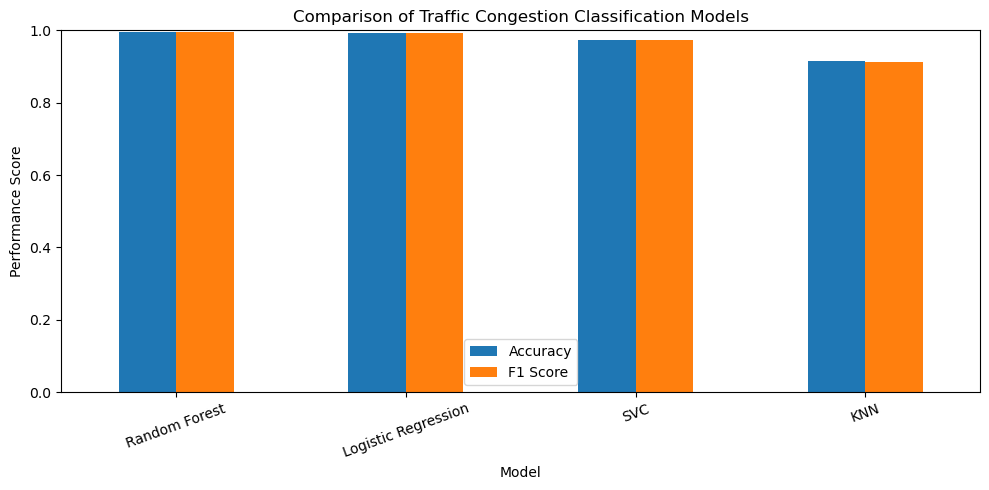

In [19]:
# Create a bar chart to compare all four models
results_df.set_index("Model")[["Accuracy", "F1 Score"]].plot(
    kind="bar",       # Create a bar chart
    figsize=(10, 5)   # Set the chart size
)

# Add a title to the chart
plt.title("Comparison of Traffic Congestion Classification Models")

# Label the vertical axis
plt.ylabel("Performance Score")

# Set the score range from 0 to 1
plt.ylim(0, 1)

# Rotate model names for better readability
plt.xticks(rotation=20)

# Display the legend
plt.legend()

# Adjust spacing to prevent labels from overlapping
plt.tight_layout()

# Display the chart
plt.show()

### Create a confusion matrix for the best model

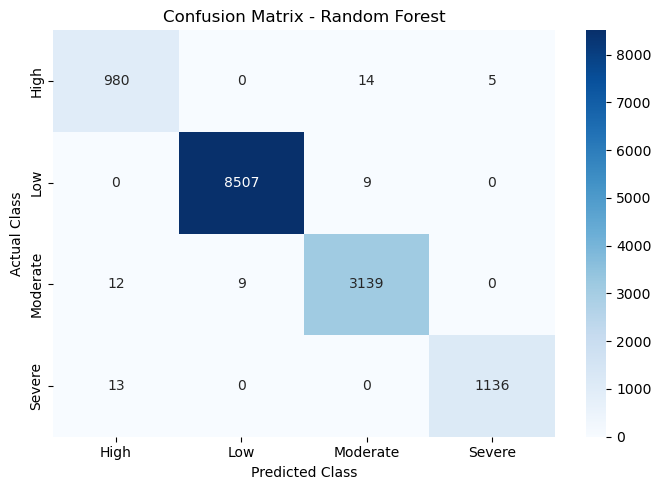

Classification Report - Random Forest
              precision    recall  f1-score   support

        High       0.98      0.98      0.98       999
         Low       1.00      1.00      1.00      8516
    Moderate       0.99      0.99      0.99      3160
      Severe       1.00      0.99      0.99      1149

    accuracy                           1.00     13824
   macro avg       0.99      0.99      0.99     13824
weighted avg       1.00      1.00      1.00     13824



In [20]:
# Find the name of the model with the highest F1 score
best_model_name = results_df.iloc[0]["Model"]

# Select the predictions made by the best model
if best_model_name == "Logistic Regression":
    best_predictions = y_pred_lr

elif best_model_name == "SVC":
    best_predictions = y_pred_svc

elif best_model_name == "KNN":
    best_predictions = y_pred_knn

else:
    best_predictions = y_pred_rf

# Calculate the confusion matrix
cm = confusion_matrix(y_test, best_predictions)

# Create a heatmap to visualize the confusion matrix
plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,          # Display the numbers in each cell
    fmt="d",             # Show numbers as integers
    cmap="Blues",        # Use a blue color scheme
    xticklabels=np.unique(y_test),
    yticklabels=np.unique(y_test)
)

# Add the chart title and axis labels
plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

# Adjust the chart layout
plt.tight_layout()

# Display the chart
plt.show()

# Print the classification report
print(f"Classification Report - {best_model_name}")
print(classification_report(
    y_test,
    best_predictions,
    zero_division=0
))

### Save the best model

In [21]:
# Import joblib to save the trained model
import joblib

# Find the model with the highest weighted F1 score
best_model_name = results_df.iloc[0]["Model"]

# Select the best trained model
if best_model_name == "Logistic Regression":
    best_model = logistic_model

elif best_model_name == "SVC":
    best_model = svc_model

elif best_model_name == "KNN":
    best_model = knn_model

else:
    best_model = rf_model

# Create a folder to store the trained model if needed
import os
os.makedirs("../../models", exist_ok=True)

# Save the selected model to a file
joblib.dump(
    best_model,
    "../../models/best_traffic_congestion_model.pkl"
)

# Display the saved model's name and location
print("Best model:", best_model_name)
print("Model saved successfully!")
print("Location: models/best_traffic_congestion_model.pkl")

Best model: Random Forest
Model saved successfully!
Location: models/best_traffic_congestion_model.pkl


## Conclusion

In this project, four machine learning classification algorithms were trained to predict traffic congestion:

1. Logistic Regression
2. Support Vector Classifier (SVC)
3. K-Nearest Neighbors (KNN)
4. Random Forest Classifier

The models were evaluated using accuracy, precision, recall, and weighted F1 score. Their performance was compared using a table and a bar chart, and a confusion matrix was generated for the best-performing model.

The model with the highest weighted F1 score was selected and saved for future use.

This experiment provides a baseline for traffic congestion classification. Further improvements may include feature selection, hyperparameter tuning, and testing on future time periods to evaluate real-world prediction performance.